## imports

In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

## salt and pepper effect

In [13]:
clean = cv2.imread("image.png", cv2.IMREAD_GRAYSCALE)

# Gaussian noise: small random changes on every pixel
noisy = clean.astype(np.float32) + np.random.normal(0, 25, clean.shape)

# Salt & pepper noise: random pixels forced to white or black
rand = np.random.rand(*clean.shape)
noisy[rand < 0.02] = 0
noisy[rand > 0.98] = 255

img = np.clip(noisy, 0, 255).astype(np.uint8)
cv2.imwrite("noisy.jpg", img)

True

## read image

In [14]:
img = cv2.imread("noisy.jpg", cv2.IMREAD_GRAYSCALE)   # put your image path here

if img is None:
    raise FileNotFoundError("Image not found, check the path")

print("Shape (height, width):", img.shape)
print("Pixel values range from", img.min(), "to", img.max())
print("Top-left 3x3 pixels:\n", img[:3, :3])

Shape (height, width): (128, 256)
Pixel values range from 0 to 255
Top-left 3x3 pixels:
 [[246 235 228]
 [252 209 233]
 [201   0 199]]


## mean and gaussian filters

In [24]:
# Mean filter: every neighbor counts equally
mean_filter = np.ones((3, 3), np.float32) / 9

# Gaussian filter: the center pixel counts more than the edges
gaussian_filter = np.array([[1, 2, 1],
                            [2, 4, 2],
                            [1, 2, 1]], np.float32) / 16

print("Mean filter:\n", mean_filter)
print("Gaussian filter:\n", gaussian_filter)
print("Sum of weights:", mean_filter.sum(), gaussian_filter.sum())   # both 1, so brightness stays the same

Mean filter:
 [[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]
Gaussian filter:
 [[0.0625 0.125  0.0625]
 [0.125  0.25   0.125 ]
 [0.0625 0.125  0.0625]]
Sum of weights: 1.0 1.0


In [25]:
def apply_filter(image, kernel):
    h, w = image.shape

    # add a 1-pixel border (copy of edge pixels) so border pixels also have 8 neighbors
    padded = np.pad(image.astype(np.float32), 1, mode="edge")

    result = np.zeros((h, w), np.float32)

    # for each of the 9 filter positions, shift the image and add weight * shifted image
    for i in range(3):
        for j in range(3):
            result += kernel[i, j] * padded[i:i + h, j:j + w]

    return np.clip(result, 0, 255).astype(np.uint8)


denoised_mean = apply_filter(img, mean_filter)
denoised_gauss = apply_filter(img, gaussian_filter)

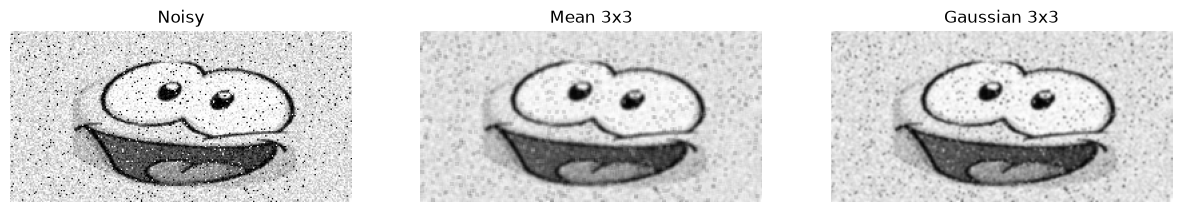

True

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img, cmap="gray");             axes[0].set_title("Noisy")
axes[1].imshow(denoised_mean, cmap="gray");   axes[1].set_title("Mean 3x3")
axes[2].imshow(denoised_gauss, cmap="gray");  axes[2].set_title("Gaussian 3x3")
for a in axes:
    a.axis("off")
plt.show()

cv2.imwrite("denoised_mean.jpg", denoised_mean)
cv2.imwrite("denoised_gaussian.jpg", denoised_gauss)